In [1]:
variable_name = "" # @param {"type":"string"}
import tensorflow as tf
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


طول مولد التدريب (عدد الـ Batches): 3
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/2
3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.4375 - loss: 0.9667 - val_accuracy: 0.5625 - val_loss: 0.6870
Epoch 2/2
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.3958 - loss: 0.8939 - val_accuracy: 0.4375 - val_loss: 0.9329
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
تم استخراج الميزات بنجاح، شكل المصفوفة: (5, 128)


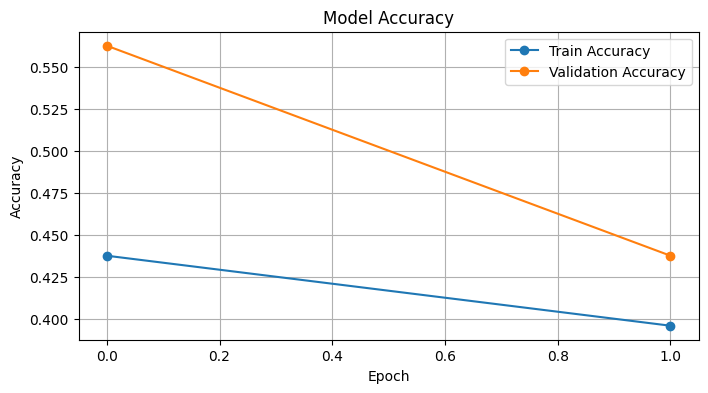

Epoch 1/2
3/3 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.4792 - loss: 0.7363 - val_accuracy: 0.4375 - val_loss: 0.9246
Epoch 2/2
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.4792 - loss: 0.7125 - val_accuracy: 0.4375 - val_loss: 0.9197


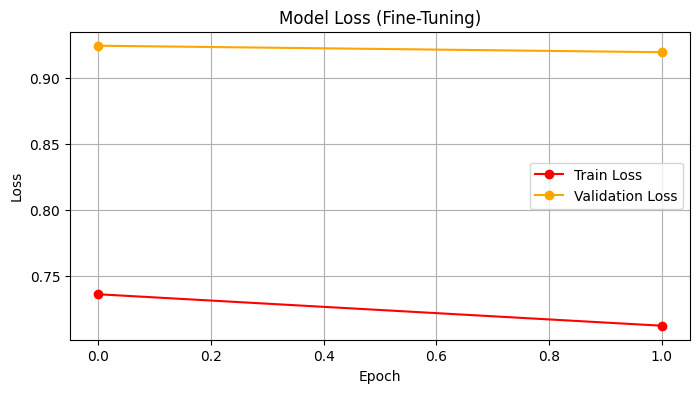

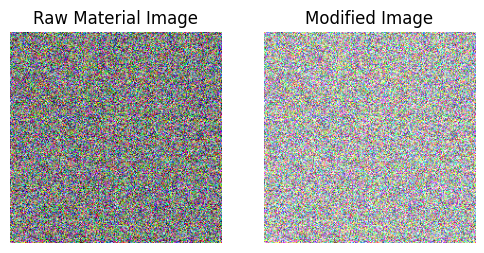

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. إنشاء بيانات تجريبية وهمية متكاملة لضمان عدم وجود أخطاء في المسارات
num_samples = 64
dummy_images = np.random.rand(num_samples, 224, 224, 3).astype('float32')
dummy_labels = np.random.randint(0, 2, size=(num_samples,))

# تقسيمها إلى تدريب واختبار
train_images, test_images = dummy_images[:48], dummy_images[48:]
train_labels, test_labels = dummy_labels[:48], dummy_labels[48:]

# 2. إنشاء مولد بيانات التدريب والاختبار
train_datagen = ImageDataGenerator(rescale=1./255, rotation_range=20, horizontal_flip=True)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow(train_images, train_labels, batch_size=16)
test_generator = test_datagen.flow(test_images, test_labels, batch_size=16, shuffle=False)

# 3. طباعة طول train generator (عدد الدفعات / Batches)
print("طول مولد التدريب (عدد الـ Batches):", len(train_generator))

# 4. بناء وتجهيز النموذج باستخدام MobileNetV2
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=outputs)
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 5. تدريب النموذج واستخراج الميزات
history = model.fit(train_generator, epochs=2, validation_data=test_generator)

# استخراج الميزات من طبقة التجميع
feature_extractor = Model(inputs=model.input, outputs=model.layers[-2].output)
extracted_features = feature_extractor.predict(test_images[:5])
print("تم استخراج الميزات بنجاح، شكل المصفوفة:", extracted_features.shape)

# 6. رسم منحنيات الدقة (Accuracy)
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# 7. ضبط دقيق للنموذج (Fine-Tuning) ورسم منحنيات الخسارة (Loss)
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='binary_crossentropy', metrics=['accuracy'])
history_fine = model.fit(train_generator, epochs=2, validation_data=test_generator)

plt.figure(figsize=(8, 4))
plt.plot(history_fine.history['loss'], label='Train Loss', color='red', marker='o')
plt.plot(history_fine.history['val_loss'], label='Validation Loss', color='orange', marker='o')
plt.title('Model Loss (Fine-Tuning)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# 8. رسم وعرض صورة اختبارية للمواد الخام والمعدلة
plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(test_images[0])
plt.title('Raw Material Image')
plt.axis('off')

plt.subplot(1, 2, 2)
processed_img = tf.image.adjust_brightness(test_images[0], 0.2).numpy()
plt.imshow(processed_img)
plt.title('Modified Image')
plt.axis('off')
plt.show()